In [43]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from scipy.special import expit
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor 
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [44]:
# [ 도미 ]
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0,
33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0,
610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# [ 빙어 ]
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [45]:
# Quiz
# 1. 도미와 빙어 구분하는 머신러닝을 구성하시오 - 길이 21, 무게 90의 고기를 예측하시오(LogisticRegression())알고리즘을 사용)
# 2. 도미,빙어 길이ㅣ와 무게의 산점도 그래프를 출력하시오
# 3. 길이25, 무게150의 생선을 예측하시오

In [ ]:
# 데이터 전처리
length = bream_length+smelt_length # 둘다 리스트라 더하면 합쳐짐
weight = bream_weight+smelt_weight

data= np.column_stack((length,weight))
label = ['도미']*35+['빙어']*14
len(smelt_length)

14

In [47]:
# 데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label)
train_data

array([[ 33. , 700. ],
       [ 29. , 430. ],
       [ 30. , 390. ],
       [ 36. , 850. ],
       [ 29. , 363. ],
       [ 12.2,  12.2],
       [ 14.3,  19.7],
       [ 35. , 700. ],
       [ 35. , 720. ],
       [ 13. ,  12.2],
       [ 41. , 950. ],
       [ 11.8,   9.9],
       [ 26.3, 290. ],
       [ 31. , 500. ],
       [ 36. , 714. ],
       [ 32. , 600. ],
       [ 30. , 450. ],
       [ 10.5,   7.5],
       [ 29.7, 450. ],
       [ 12.4,  13.4],
       [ 33. , 700. ],
       [ 34. , 575. ],
       [ 35. , 725. ],
       [ 11.8,  10. ],
       [ 26.5, 340. ],
       [ 10.6,   7. ],
       [ 33.5, 650. ],
       [ 34. , 685. ],
       [ 31.5, 500. ],
       [ 33.5, 610. ],
       [ 32. , 340. ],
       [ 32. , 600. ],
       [ 15. ,  19.9],
       [ 12. ,   9.8],
       [ 25.4, 242. ],
       [ 34.5, 620. ]])

In [48]:
# 정규화 # 
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)


In [72]:
# 데이터 학습
lr =LogisticRegression()
lr.fit(train_scaled,train_label)

# 데이터 예측
predict = lr.predict(test_data)
# ※ test_scaled로! 정규화한 데이터로 학습함

# 정확도
score = lr.score(train_scaled,train_label)
score1 = lr.score(test_scaled,test_label)
score,score1

(1.0, 1.0)

In [ ]:
decision = lr.decision_function(test_scaled[:5])
np.round(decision,decimals=4) # 소숫점4자리에서 반올림
expit(decision) # 0~1사이 확률로 바꿈

array([0.00107521, 0.91694889, 0.00116905, 0.9179743 , 0.00095   ])

In [94]:
# Quiz
# 1. 도미와 빙어 구분하는 머신러닝을 구성하시오 - 길이 21, 무게 90의 고기를 예측하시오(LogisticRegression())알고리즘을 사용)
# 2. 도미,빙어 길이와 무게의 산점도 그래프를 출력하시오
# 3. 길이25, 무게150의 생선을 예측하시오
# in_data = input('길이,무게: 예) 21,90')
in_data = '21,90'
in_data1 = '25,150'
in_data = list(map(float,in_data.split(',')))
in_data1 = list(map(float,in_data1.split(',')))

new_data = ss.transform([in_data])
new_data1 = ss.transform([in_data1])

result = lr.predict(new_data)
result1 = lr.predict_proba(new_data)
result2 = lr.predict(new_data1)
result3 = lr.predict_proba(new_data1)
result4 = result1.max()
result5 = result3.max()
# if result[0] == '도미':
#     result2 = result1[0][0]
# else:
#     result2 = result1[0][1]

print(f'생선:{result[0]},확률:{result4*100:.2f}%')
print(f'생선:{result2[0]},확률:{result5*100:.2f}%')


생선:빙어,확률:55.94%
생선:도미,확률:68.41%


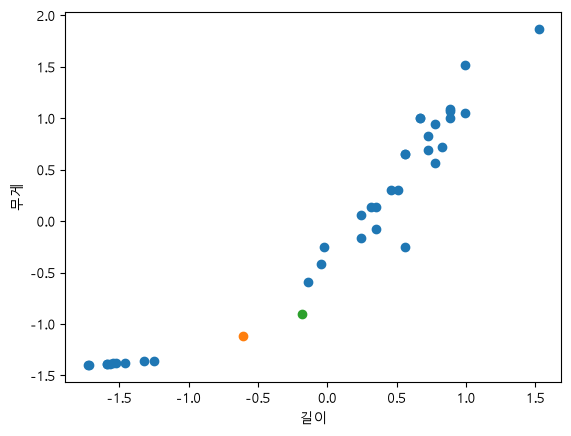

In [96]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_data[:,0],new_data[:,1])
plt.scatter(new_data1[:,0],new_data1[:,1])
plt.plot()
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()